# 01 - Exploración Descriptiva y Matrices de Correlación de Spearman

## Objetivo
- Exploración descriptiva de las métricas de evaluación
- Matrices de correlación de Spearman para identificar redundancias
- Selección de Variables de Respuesta (VR)
- Reducción de dimensionalidad (PCA)

## Datos
- `metric_comparison_source_data_cleaned.csv`: métricas tradicionales
- `final_judge_results.csv`: evaluaciones LLM-as-Judge

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from scipy import stats
from sklearn.decomposition import PCA
from pathlib import Path

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 8)})

DATA_DIR = Path("..") / "part_i" 

## 1. Carga de datos

In [2]:
df_metrics = pl.read_csv(DATA_DIR / "metric_comparison_source_data_cleaned.csv")
df_judge = pl.read_csv(DATA_DIR / "final_judge_results.csv")

print(f"Métricas tradicionales: {df_metrics.shape}")
print(f"Evaluación agéntica: {df_judge.shape}")
display(df_metrics.head())
display(df_judge.head())

Métricas tradicionales: (9954, 6)
Evaluación agéntica: (2133, 9)


nro_pregunta,nro_subpregunta,estrategia,id_modelo_especialista,metrica,valor
i64,i64,str,str,str,f64
1,1,"""llm_responses_no_rag""","""gpt-5-nano""","""exact_match""",0.0
1,1,"""llm_responses_no_rag""","""gpt-5-nano""","""token_f1""",0.1976
1,1,"""llm_responses_no_rag""","""gpt-5-nano""","""jaccard_similarity""",0.1096
1,1,"""llm_responses_no_rag""","""gpt-5-nano""","""levenshtein_similarity""",0.1734
1,1,"""llm_responses_no_rag""","""gpt-5-nano""","""character_error_rate""",3.8154


numero_pregunta,numero_subpregunta,modelo_juez,sistema,modelo_respuesta,score_respuesta_correcta,reason_respuesta_correcta,score_precision_legal,reason_precision_legal
i64,i64,str,str,str,f64,str,f64,str
1,1,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",0.5,"""La respuesta es parcialmente c…",0.0,"""La respuesta no cita ningún ar…"
1,2,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",1.0,"""La respuesta es completamente …",0.0,"""La respuesta no cita ningún ar…"
1,3,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",1.0,"""La respuesta provista concluye…",0.0,"""La respuesta no cita ningún ar…"
2,1,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",0.0,"""La respuesta provista concluye…",0.0,"""La salida no cita ningún artíc…"
2,2,"""grok_4_1_fast_free""","""llm_responses_no_rag""","""gpt-5-nano""",0.5,"""La respuesta proporcionada no …",0.0,"""La respuesta no cita ningún ar…"


In [3]:
# Valores únicos de las variables categóricas
print("Estrategias:", df_metrics["estrategia"].unique().to_list())
print("Modelos:", df_metrics["id_modelo_especialista"].unique().to_list())
print("Métricas:", df_metrics["metrica"].unique().to_list())
print(f"\nPreguntas únicas: {df_metrics.select('nro_pregunta', 'nro_subpregunta').unique().height}")

Estrategias: ['llm_responses_no_rag', 'llm_responses_base_rag', 'llm_responses_agentic_rag']
Modelos: ['gpt-5-mini', 'gpt-5-nano', 'gpt-5']
Métricas: ['sbert_similarity_spanish', 'rouge_l', 'jaccard_similarity', 'word_count_ratio', 'bleu', 'rouge_2', 'rouge_1', 'length_ratio', 'token_f1', 'character_error_rate', 'bertscore', 'sbert_similarity_multilingual', 'exact_match', 'levenshtein_similarity']

Preguntas únicas: 79


## 2. Pivotar métricas a formato ancho

Para calcular correlaciones necesitamos una fila por observación (pregunta × estrategia × modelo) y una columna por métrica.

In [4]:
df_wide = df_metrics.pivot(
    on="metrica",
    index=["nro_pregunta", "nro_subpregunta", "estrategia", "id_modelo_especialista"],
    values="valor",
)

METRICAS_TRADICIONALES = [
    "token_f1", "jaccard_similarity", "levenshtein_similarity",
    "character_error_rate", "bleu", "rouge_1", "rouge_2", "rouge_l",
    "sbert_similarity_multilingual", "sbert_similarity_spanish",
    "bertscore", "length_ratio", "word_count_ratio",
]

print(f"Formato ancho: {df_wide.shape}")
df_wide.head()

Formato ancho: (711, 18)


nro_pregunta,nro_subpregunta,estrategia,id_modelo_especialista,exact_match,token_f1,jaccard_similarity,levenshtein_similarity,character_error_rate,bleu,rouge_1,rouge_2,rouge_l,sbert_similarity_multilingual,sbert_similarity_spanish,bertscore,length_ratio,word_count_ratio
i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,1,"""llm_responses_no_rag""","""gpt-5-nano""",0.0,0.1976,0.1096,0.1734,3.8154,0.018,0.2084,0.0684,0.1363,0.8076,0.7965,0.7095,4.6158,4.55
1,1,"""llm_responses_no_rag""","""gpt-5-mini""",0.0,0.1416,0.0762,0.1087,7.3672,0.0135,0.1436,0.0561,0.0876,0.6086,0.7674,0.7041,8.2655,8.175
1,1,"""llm_responses_no_rag""","""gpt-5""",0.0,0.2646,0.1525,0.1495,4.7985,0.0342,0.2198,0.1149,0.1393,0.8465,0.8506,0.7365,5.6422,5.975
1,1,"""llm_responses_base_rag""","""gpt-5-nano""",0.0,0.2023,0.1125,0.1044,7.806,0.0274,0.1571,0.0909,0.0996,0.7875,0.8039,0.7439,8.7156,9.1375
1,1,"""llm_responses_base_rag""","""gpt-5-mini""",0.0,0.2197,0.1234,0.1094,7.4331,0.035,0.1698,0.1026,0.1233,0.7276,0.7969,0.7378,8.3465,8.525


## 3. Estadística descriptiva de métricas tradicionales

In [5]:
desc_stats = df_metrics.group_by("metrica").agg(
    pl.col("valor").mean().alias("media"),
    pl.col("valor").median().alias("mediana"),
    pl.col("valor").std().alias("std"),
    pl.col("valor").min().alias("min"),
    pl.col("valor").quantile(0.25).alias("Q1"),
    pl.col("valor").quantile(0.75).alias("Q3"),
    pl.col("valor").max().alias("max"),
    pl.col("valor").count().alias("n"),
).sort("metrica")

display(desc_stats)

metrica,media,mediana,std,min,Q1,Q3,max,n
str,f64,f64,f64,f64,f64,f64,f64,u32
"""bertscore""",0.674173,0.6961,0.141621,0.0,0.6782,0.7214,0.8444,711
"""bleu""",0.037264,0.0197,0.046386,0.0,0.0103,0.045,0.3348,711
"""character_error_rate""",4.142596,3.493,2.880206,0.583,1.9735,5.6496,16.7104,711
"""exact_match""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,711
"""jaccard_similarity""",0.135276,0.1264,0.069257,0.0,0.0934,0.1674,0.4588,711
…,…,…,…,…,…,…,…,…
"""rouge_l""",0.154613,0.1406,0.084182,0.0,0.105,0.1874,0.5714,711
"""sbert_similarity_multilingual""",0.659702,0.6966,0.17045,0.0279,0.5908,0.7769,0.9402,711
"""sbert_similarity_spanish""",0.708143,0.7573,0.177392,0.0336,0.6737,0.8106,0.9212,711


## 3.B. Estadística descriptiva de métricas agénticas

Se analiza la distribución de los scores asignados por cada modelo juez para `score_respuesta_correcta` y `score_precision_legal`. Los valores válidos según las rúbricas son únicamente: **0.0, 0.25, 0.5, 0.75 y 1.0**. Cualquier valor fuera de este conjunto indica que el modelo juez no respetó la escala prescrita.

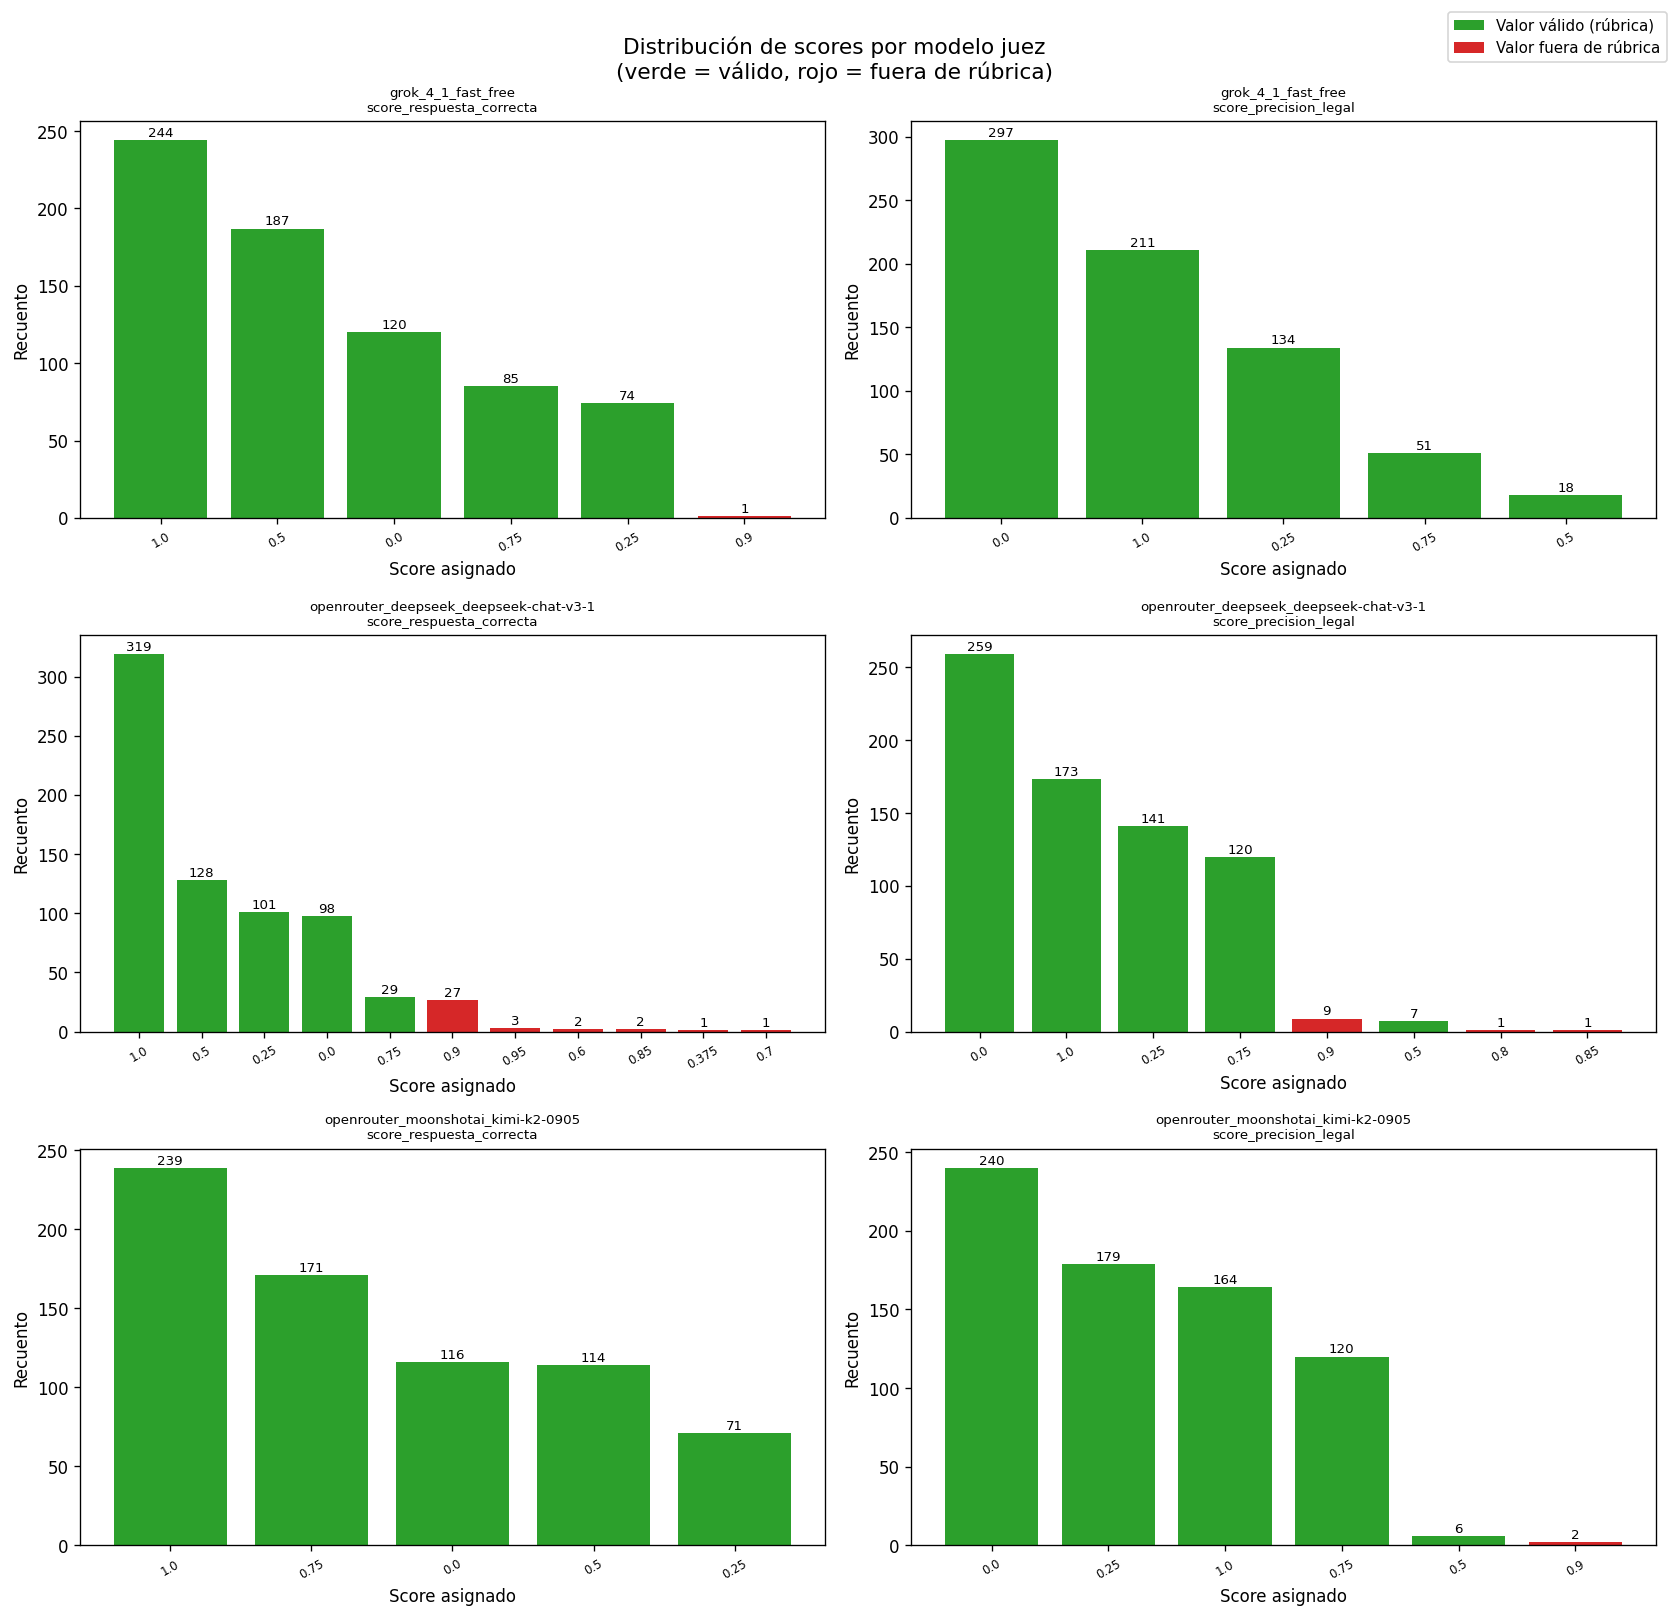

In [6]:
RUBRICA_VALORES = [0.0, 0.25, 0.5, 0.75, 1.0]
JUDGE_SCORES = ["score_respuesta_correcta", "score_precision_legal"]
JUDGE_COL = "modelo_juez"

jueces = sorted(df_judge[JUDGE_COL].unique().to_list())
n_jueces = len(jueces)

fig, axes = plt.subplots(n_jueces, len(JUDGE_SCORES), figsize=(14, 4.5 * n_jueces))
if n_jueces == 1:
    axes = axes.reshape(1, -1)

for row_idx, juez in enumerate(jueces):
    df_j = df_judge.filter(pl.col(JUDGE_COL) == juez)
    for col_idx, score_col in enumerate(JUDGE_SCORES):
        ax = axes[row_idx, col_idx]
        # Contar cada valor único (incluyendo fuera de rúbrica)
        counts_series = df_j[score_col].value_counts().sort("count", descending=True)
        all_values = counts_series[score_col].to_list()
        all_counts = counts_series["count"].to_list()

        colors = ["#2ca02c" if v in RUBRICA_VALORES else "#d62728" for v in all_values]
        bars = ax.bar([str(v) for v in all_values], all_counts, color=colors)

        for bar, cnt in zip(bars, all_counts):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    str(cnt), ha="center", va="bottom", fontsize=8)

        ax.set_title(f"{juez.split('/')[-1]}\n{score_col}", fontsize=8)
        ax.set_xlabel("Score asignado")
        ax.set_ylabel("Recuento")
        ax.tick_params(axis="x", labelsize=7, rotation=30)

# Leyenda global
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#2ca02c", label="Valor válido (rúbrica)"),
    Patch(facecolor="#d62728", label="Valor fuera de rúbrica"),
]
fig.legend(handles=legend_handles, loc="upper right", fontsize=9, bbox_to_anchor=(1.0, 1.0))
fig.suptitle("Distribución de scores por modelo juez\n(verde = válido, rojo = fuera de rúbrica)", fontsize=13)
plt.tight_layout()
plt.show()

In [7]:
# Contar violaciones por juez y por métrica
violation_rows = []

for juez in jueces:
    df_j = df_judge.filter(pl.col(JUDGE_COL) == juez)
    for score_col in JUDGE_SCORES:
        n_total = df_j.height
        n_invalidos = df_j.filter(~pl.col(score_col).is_in(RUBRICA_VALORES)).height
        pct = 100 * n_invalidos / n_total if n_total > 0 else 0.0
        violation_rows.append({
            "modelo_juez": juez,
            "metrica": score_col,
            "n_total": n_total,
            "n_invalidos": n_invalidos,
            "pct_invalidos": round(pct, 2),
        })

df_violations = pl.DataFrame(violation_rows).sort(["modelo_juez", "metrica"])
print("Violaciones de rúbrica por juez:")
display(df_violations)

# Detalle de los valores inválidos encontrados
print("\nValores inválidos detectados (sample):")
invalidos_sample = df_judge.filter(
    ~pl.col("score_respuesta_correcta").is_in(RUBRICA_VALORES)
    | ~pl.col("score_precision_legal").is_in(RUBRICA_VALORES)
).select([JUDGE_COL, "score_respuesta_correcta", "score_precision_legal"])
display(invalidos_sample.unique(subset=[JUDGE_COL, "score_respuesta_correcta", "score_precision_legal"]).sort(JUDGE_COL))

Violaciones de rúbrica por juez:


modelo_juez,metrica,n_total,n_invalidos,pct_invalidos
str,str,i64,i64,f64
"""grok_4_1_fast_free""","""score_precision_legal""",711,0,0.0
"""grok_4_1_fast_free""","""score_respuesta_correcta""",711,1,0.14
"""openrouter_deepseek_deepseek-c…","""score_precision_legal""",711,11,1.55
"""openrouter_deepseek_deepseek-c…","""score_respuesta_correcta""",711,36,5.06
"""openrouter_moonshotai_kimi-k2-…","""score_precision_legal""",711,2,0.28
"""openrouter_moonshotai_kimi-k2-…","""score_respuesta_correcta""",711,0,0.0



Valores inválidos detectados (sample):


modelo_juez,score_respuesta_correcta,score_precision_legal
str,f64,f64
"""grok_4_1_fast_free""",0.9,0.5
"""openrouter_deepseek_deepseek-c…",0.6,0.25
"""openrouter_deepseek_deepseek-c…",0.95,0.0
"""openrouter_deepseek_deepseek-c…",0.85,0.8
"""openrouter_deepseek_deepseek-c…",1.0,0.85
…,…,…
"""openrouter_deepseek_deepseek-c…",1.0,0.9
"""openrouter_deepseek_deepseek-c…",0.375,0.0
"""openrouter_deepseek_deepseek-c…",0.9,1.0


## 3.C. Imputación de valores que no respetan la rúbrica

### Estrategia: redondeo al valor de rúbrica más cercano (distancia absoluta mínima)

Los modelos juez deben asignar scores dentro del conjunto ordenado **{0.0, 0.25, 0.5, 0.75, 1.0}**. Cuando un modelo produce un valor fuera de esta grilla (p. ej. 0.33, 0.9, 0.6) se interpreta como un error de calibración numérica, no como una intención de usar una escala diferente.

**Procedimiento sistemático:**

Para cada score inválido $x$, se calcula la distancia absoluta $|x - r|$ con cada valor de rúbrica $r \in \{0.0, 0.25, 0.5, 0.75, 1.0\}$ y se asigna el $r^*$ que minimiza esa distancia:

$$r^* = \arg\min_{r \in \mathcal{R}} |x - r|$$

En caso de empate exacto entre dos valores (p. ej. $x = 0.125$ equidistante a 0.0 y 0.25) se elige el **mayor** de los dos candidatos, lo que equivale a una leve inclinación hacia el reconocimiento parcial de la respuesta — criterio coherente con la dirección conservadora de las rúbricas legales.

**Justificación:**

1. **Mínima intervención**: el valor imputado es el más cercano al original, por lo que altera lo menos posible la señal del juez.
2. **Preservación del orden**: el redondeo respeta el orden relativo de los scores (un 0.4 sigue siendo mayor que un 0.3 tras la imputación).
3. **Invarianza al nivel**: no introduce sesgo sistemático hacia arriba o abajo, a diferencia de estrategias como "redondear al inmediato superior" o "reemplazar por la mediana del juez".
4. **Reproducibilidad**: el algoritmo es determinístico y no requiere información externa adicional.

Los valores válidos no se modifican en ningún caso.

In [8]:
import polars.selectors as cs

_rubrica_arr = np.array(RUBRICA_VALORES)

def impute_to_rubrica(value: float) -> float:
    """Redondea al valor de rúbrica más cercano; empates se resuelven con el mayor."""
    dists = np.abs(_rubrica_arr - value)
    min_dist = dists.min()
    candidates = _rubrica_arr[dists == min_dist]
    return float(candidates.max())  # empates: elegir el mayor

# Aplicar la imputación
df_judge_clean = df_judge.with_columns([
    pl.col(score_col)
      .map_elements(
          lambda v: impute_to_rubrica(v) if v not in RUBRICA_VALORES else v,
          return_dtype=pl.Float64,
      )
      .alias(score_col)
    for score_col in JUDGE_SCORES
])

# Verificación: no deben quedar valores fuera de rúbrica
for score_col in JUDGE_SCORES:
    n_restantes = df_judge_clean.filter(~pl.col(score_col).is_in(RUBRICA_VALORES)).height
    assert n_restantes == 0, f"Aún quedan {n_restantes} valores inválidos en {score_col}"

print("Imputación completada. Todos los valores respetan la rúbrica.")

# Mostrar los cambios realizados (score original vs. imputado)
cambios_rows = []
for score_col in JUDGE_SCORES:
    mask_invalidos = ~df_judge[score_col].is_in(RUBRICA_VALORES)
    original_vals = df_judge.filter(mask_invalidos).select([JUDGE_COL, score_col]).rename({score_col: "original"})
    imputado_vals = df_judge_clean.filter(mask_invalidos).select([score_col]).rename({score_col: "imputado"})
    df_cambio = pl.concat([original_vals, imputado_vals], how="horizontal").with_columns(
        pl.lit(score_col).alias("metrica")
    )
    cambios_rows.append(df_cambio)

if cambios_rows:
    df_cambios = pl.concat(cambios_rows).unique(
        subset=[JUDGE_COL, "metrica", "original", "imputado"]
    ).sort([JUDGE_COL, "metrica", "original"])
    print(f"\nResumen de imputaciones realizadas ({df_cambios.height} combinaciones únicas juez/metrica/valor):")
    display(df_cambios.select(["metrica", JUDGE_COL, "original", "imputado"]))
else:
    print("No se encontraron valores fuera de rúbrica.")

# Actualizar df_judge para el resto del notebook
df_judge = df_judge_clean
print(f"\ndf_judge actualizado con valores imputados: {df_judge.shape}")

Imputación completada. Todos los valores respetan la rúbrica.

Resumen de imputaciones realizadas (11 combinaciones únicas juez/metrica/valor):


metrica,modelo_juez,original,imputado
str,str,f64,f64
"""score_respuesta_correcta""","""grok_4_1_fast_free""",0.9,1.0
"""score_precision_legal""","""openrouter_deepseek_deepseek-c…",0.8,0.75
"""score_precision_legal""","""openrouter_deepseek_deepseek-c…",0.85,0.75
"""score_precision_legal""","""openrouter_deepseek_deepseek-c…",0.9,1.0
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.375,0.5
…,…,…,…
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.7,0.75
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.85,0.75
"""score_respuesta_correcta""","""openrouter_deepseek_deepseek-c…",0.9,1.0



df_judge actualizado con valores imputados: (2133, 9)


## 4. Distribución de cada métrica (boxplots)

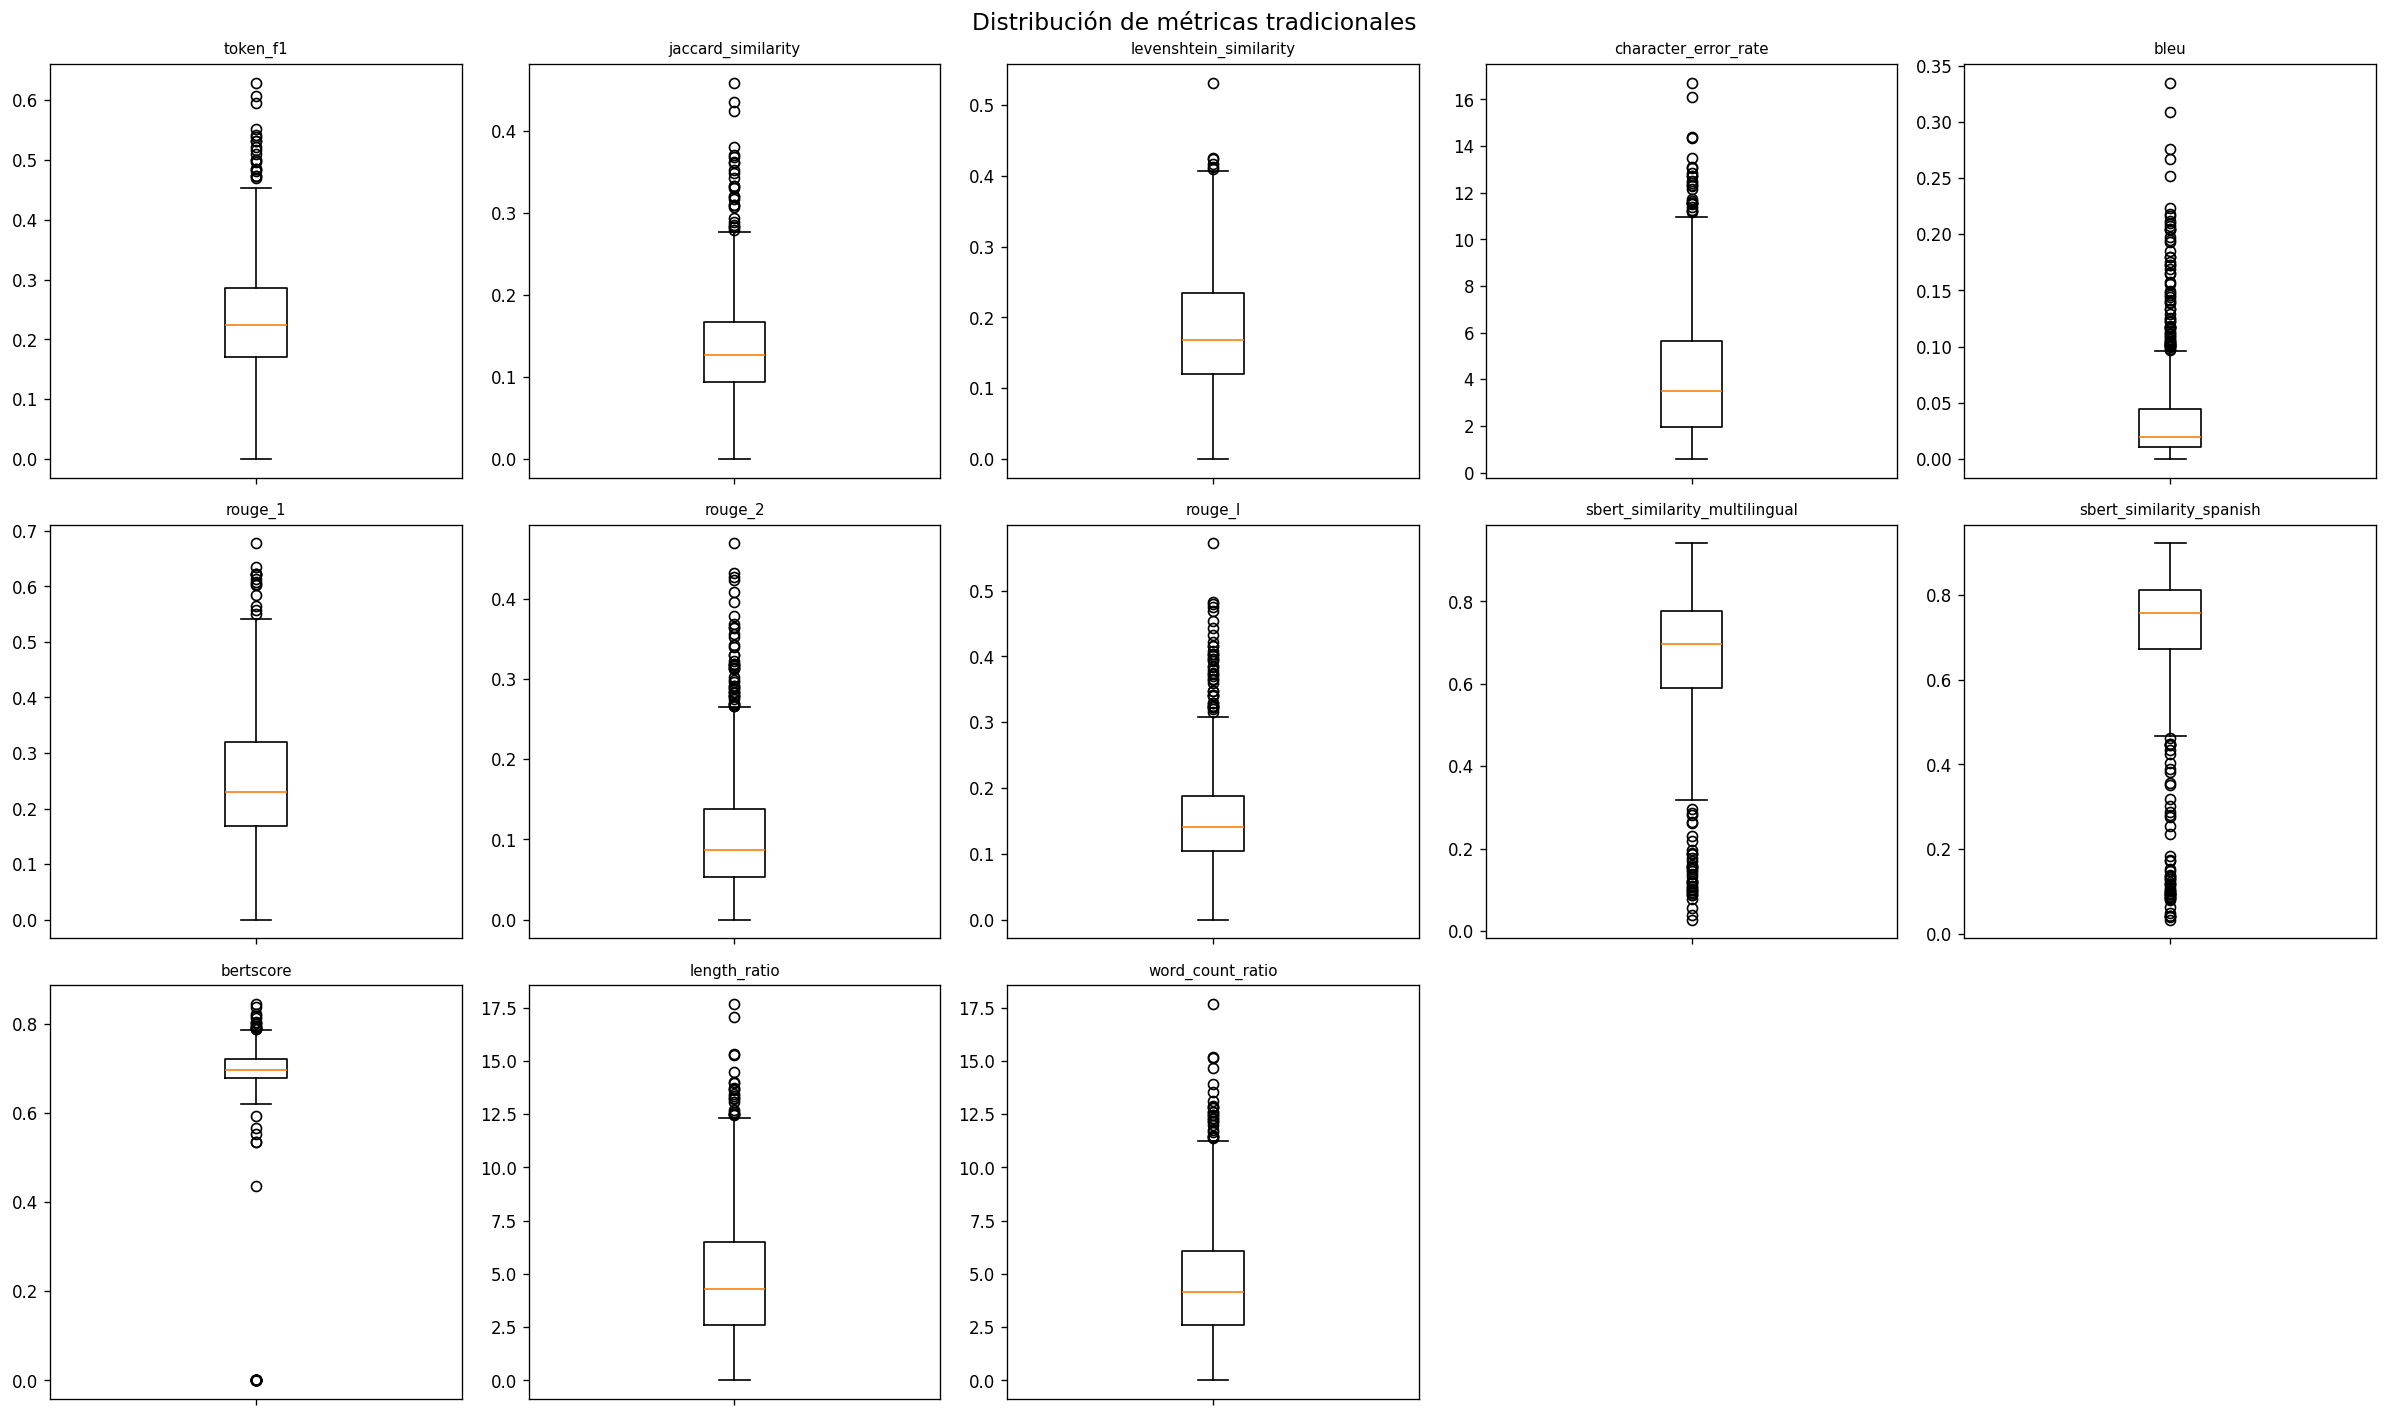

In [9]:
n_metrics_plot = len(METRICAS_TRADICIONALES)
n_cols = 5
n_rows = (n_metrics_plot + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
axes = axes.flatten()

for i, metrica in enumerate(METRICAS_TRADICIONALES):
    ax = axes[i]
    data = df_wide[metrica].drop_nulls().to_numpy()
    ax.boxplot(data, vert=True)
    ax.set_title(metrica, fontsize=9)
    ax.tick_params(axis="x", labelbottom=False)

# Ocultar ejes sobrantes
for j in range(n_metrics_plot, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distribución de métricas tradicionales", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Distribución de métricas por estrategia

/tmp/ipykernel_67015/642453632.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_strat, labels=[e.replace("llm_responses_", "") for e in estrategias], patch_artist=True)
/tmp/ipykernel_67015/642453632.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_strat, labels=[e.replace("llm_responses_", "") for e in estrategias], patch_artist=True)
/tmp/ipykernel_67015/642453632.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_strat, labels=[e.replace("llm_responses_", "") for e in estrategias], patch_artist=True)
/tmp/ipykernel_67015/642453632.py:

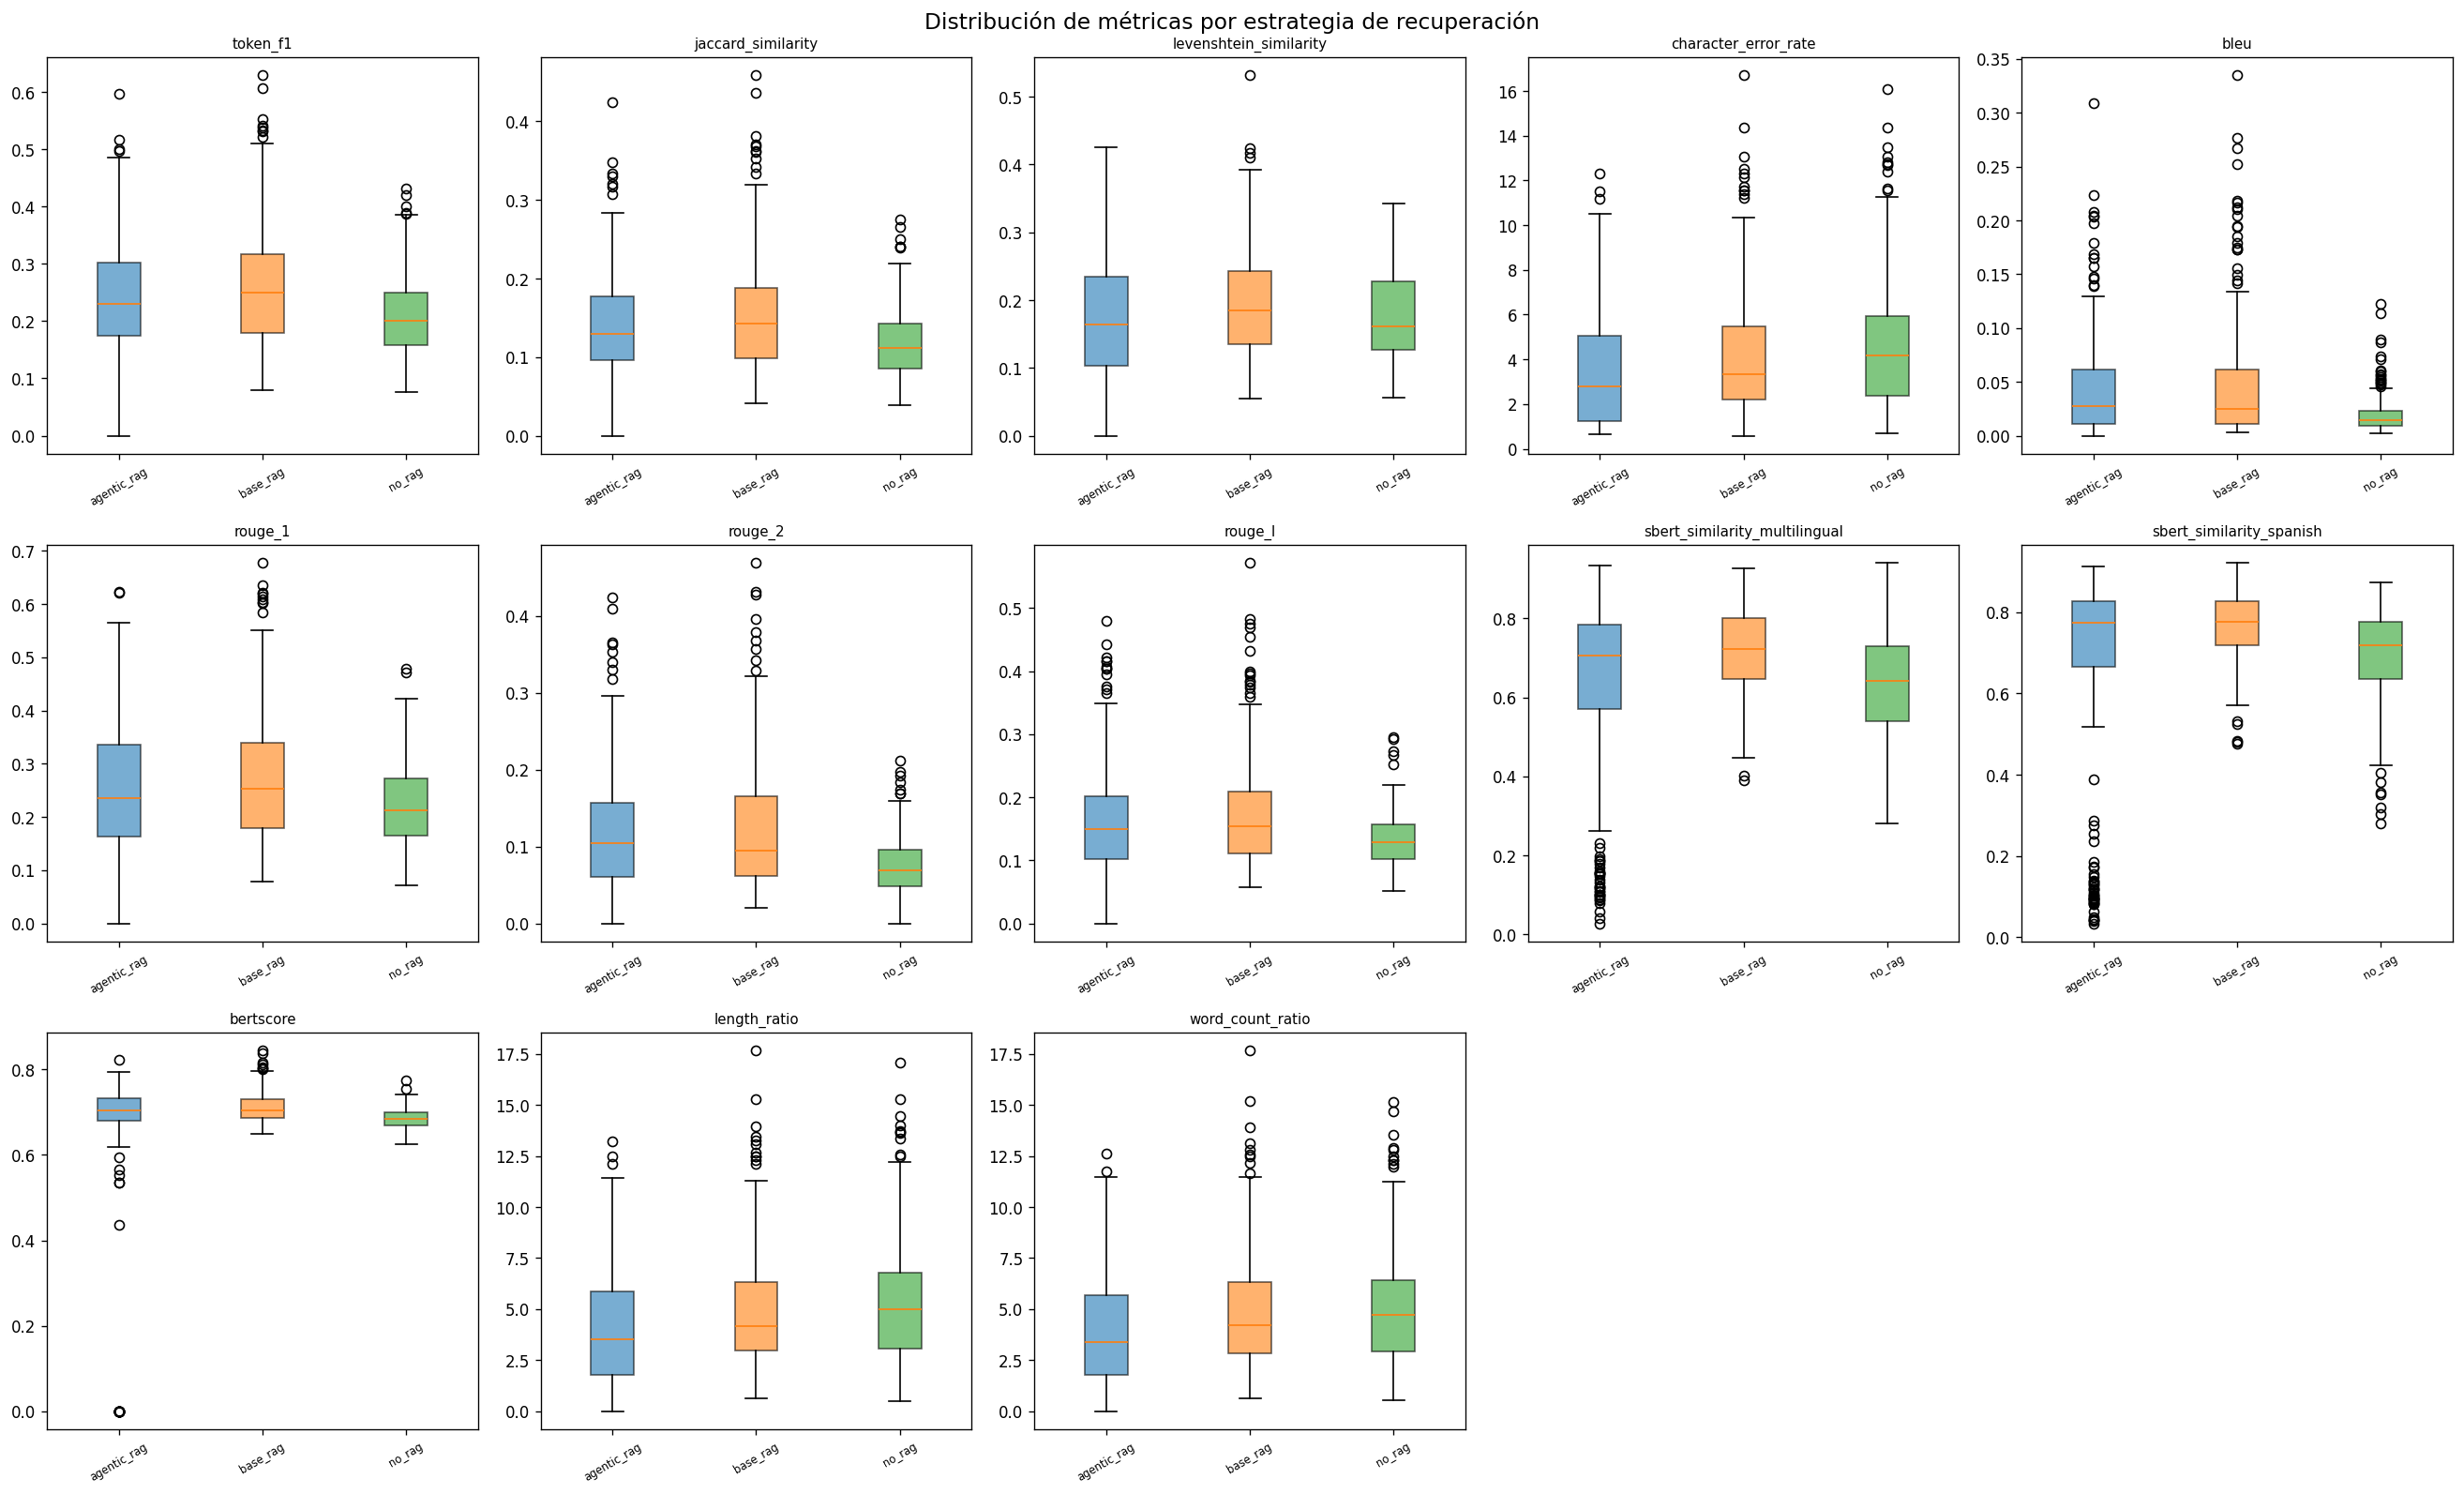

In [10]:
estrategias = sorted(df_wide["estrategia"].unique().to_list())
colores = ["#1f77b4", "#ff7f0e", "#2ca02c"]

n_cols = 5
n_rows = (len(METRICAS_TRADICIONALES) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 4.5 * n_rows))
axes = axes.flatten()

for i, metrica in enumerate(METRICAS_TRADICIONALES):
    ax = axes[i]
    data_by_strat = []
    for est in estrategias:
        vals = df_wide.filter(pl.col("estrategia") == est)[metrica].drop_nulls().to_numpy()
        data_by_strat.append(vals)
    bp = ax.boxplot(data_by_strat, labels=[e.replace("llm_responses_", "") for e in estrategias], patch_artist=True)
    for patch, color in zip(bp["boxes"], colores):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.set_title(metrica, fontsize=9)
    ax.tick_params(axis="x", rotation=30, labelsize=7)

for j in range(len(METRICAS_TRADICIONALES), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distribución de métricas por estrategia de recuperación", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Matriz de correlación de Spearman (métricas tradicionales)

Se usa Spearman porque las métricas no son normales.

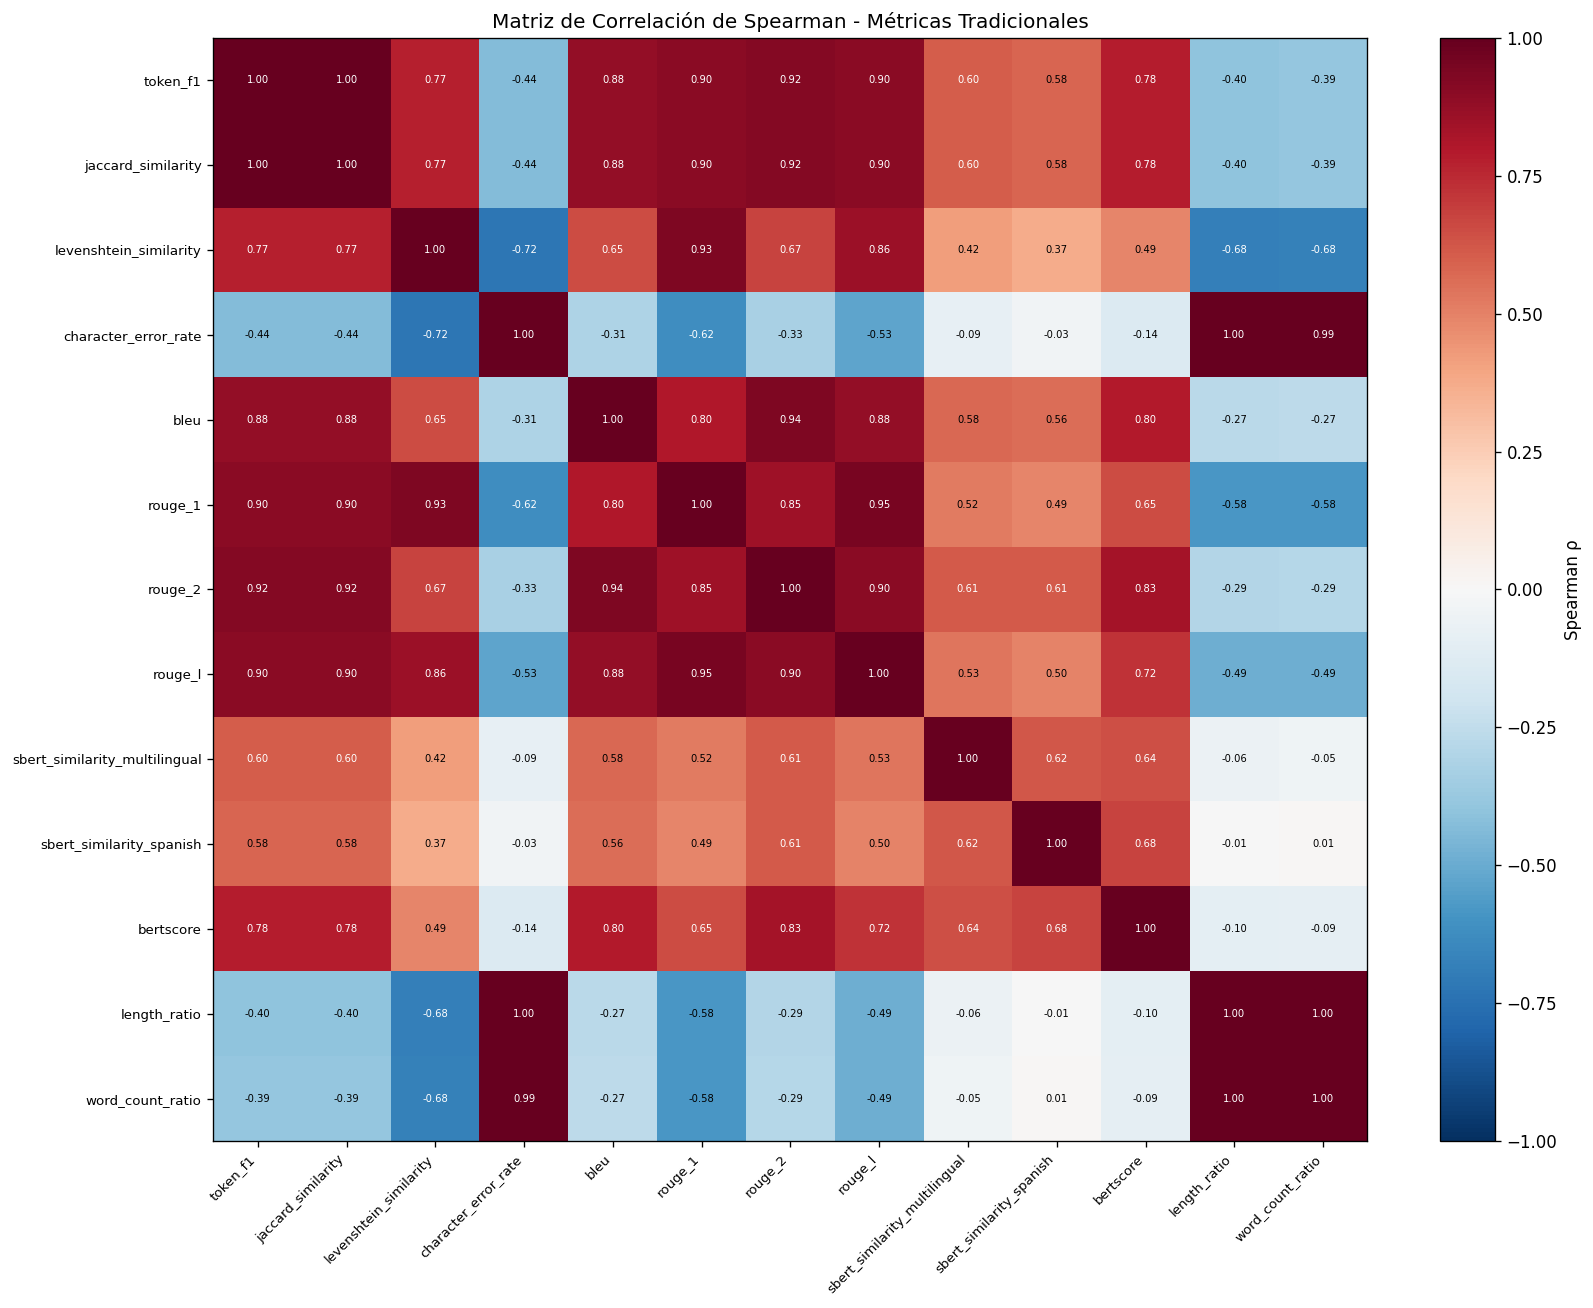

In [11]:
# Calcular matriz de correlación de Spearman
metric_data = df_wide.select(METRICAS_TRADICIONALES).to_numpy()
n_metrics = len(METRICAS_TRADICIONALES)

spearman_corr = np.zeros((n_metrics, n_metrics))
spearman_pval = np.zeros((n_metrics, n_metrics))

for i in range(n_metrics):
    for j in range(n_metrics):
        mask = ~np.isnan(metric_data[:, i]) & ~np.isnan(metric_data[:, j])
        if mask.sum() > 2:
            rho, p = stats.spearmanr(metric_data[mask, i], metric_data[mask, j])
            spearman_corr[i, j] = rho
            spearman_pval[i, j] = p
        else:
            spearman_corr[i, j] = np.nan
            spearman_pval[i, j] = np.nan

# Visualizar
fig, ax = plt.subplots(figsize=(14, 11))
im = ax.imshow(spearman_corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")

ax.set_xticks(range(n_metrics))
ax.set_yticks(range(n_metrics))
ax.set_xticklabels(METRICAS_TRADICIONALES, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(METRICAS_TRADICIONALES, fontsize=8)

# Anotar valores
for i in range(n_metrics):
    for j in range(n_metrics):
        val = spearman_corr[i, j]
        if not np.isnan(val):
            color = "white" if abs(val) > 0.6 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6, color=color)

plt.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Matriz de Correlación de Spearman - Métricas Tradicionales")
plt.tight_layout()
plt.show()

## 7. Identificar pares con alta correlación (|ρ| > 0.85)

In [12]:
UMBRAL_CORR = 0.85

pares_alta_corr = []
for i in range(n_metrics):
    for j in range(i + 1, n_metrics):
        rho = spearman_corr[i, j]
        if abs(rho) > UMBRAL_CORR:
            pares_alta_corr.append({
                "metrica_1": METRICAS_TRADICIONALES[i],
                "metrica_2": METRICAS_TRADICIONALES[j],
                "spearman_rho": round(rho, 4),
            })

df_alta_corr = pl.DataFrame(pares_alta_corr).sort("spearman_rho", descending=True)
print(f"Pares con |ρ| > {UMBRAL_CORR}: {df_alta_corr.height}")
display(df_alta_corr)

Pares con |ρ| > 0.85: 18


metrica_1,metrica_2,spearman_rho
str,str,f64
"""token_f1""","""jaccard_similarity""",1.0
"""character_error_rate""","""length_ratio""",0.9968
"""length_ratio""","""word_count_ratio""",0.9953
"""character_error_rate""","""word_count_ratio""",0.9922
"""rouge_1""","""rouge_l""",0.9474
…,…,…
"""jaccard_similarity""","""rouge_1""",0.8991
"""bleu""","""rouge_l""",0.8765
"""token_f1""","""bleu""",0.8754


## 8. Integrar métricas de juez LLM

Promediamos los scores de los 3 jueces para cada combinación.

In [13]:
# Promediar scores de jueces por pregunta/estrategia/modelo
df_judge_avg = df_judge.group_by(
    ["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"]
).agg(
    pl.col("score_respuesta_correcta").mean().alias("respuesta_correcta_avg"),
    pl.col("score_precision_legal").mean().alias("precision_legal_avg"),
    pl.col("score_respuesta_correcta").std().alias("respuesta_correcta_std"),
    pl.col("score_precision_legal").std().alias("precision_legal_std"),
)

print(f"Evaluaciones promediadas: {df_judge_avg.shape}")
display(df_judge_avg.head())

Evaluaciones promediadas: (711, 8)


numero_pregunta,numero_subpregunta,sistema,modelo_respuesta,respuesta_correcta_avg,precision_legal_avg,respuesta_correcta_std,precision_legal_std
i64,i64,str,str,f64,f64,f64,f64
9,3,"""llm_responses_base_rag""","""gpt-5""",0.0,0.333333,0.0,0.57735
20,1,"""llm_responses_base_rag""","""gpt-5-mini""",0.25,0.333333,0.0,0.144338
2,1,"""llm_responses_no_rag""","""gpt-5-nano""",0.0,0.0,0.0,0.0
12,2,"""llm_responses_no_rag""","""gpt-5-nano""",0.333333,0.0,0.144338,0.0
21,1,"""llm_responses_no_rag""","""gpt-5-nano""",0.833333,0.0,0.144338,0.0


In [14]:
# Unir con métricas tradicionales
df_combined = df_wide.join(
    df_judge_avg,
    left_on=["nro_pregunta", "nro_subpregunta", "estrategia", "id_modelo_especialista"],
    right_on=["numero_pregunta", "numero_subpregunta", "sistema", "modelo_respuesta"],
    how="left",
)

print(f"Dataset combinado: {df_combined.shape}")
print(f"Nulos en respuesta_correcta_avg: {df_combined['respuesta_correcta_avg'].null_count()}")
print(f"Nulos en precision_legal_avg: {df_combined['precision_legal_avg'].null_count()}")

Dataset combinado: (711, 22)
Nulos en respuesta_correcta_avg: 27
Nulos en precision_legal_avg: 27


## 9. Correlación Spearman: métricas tradicionales vs. evaluación agéntica

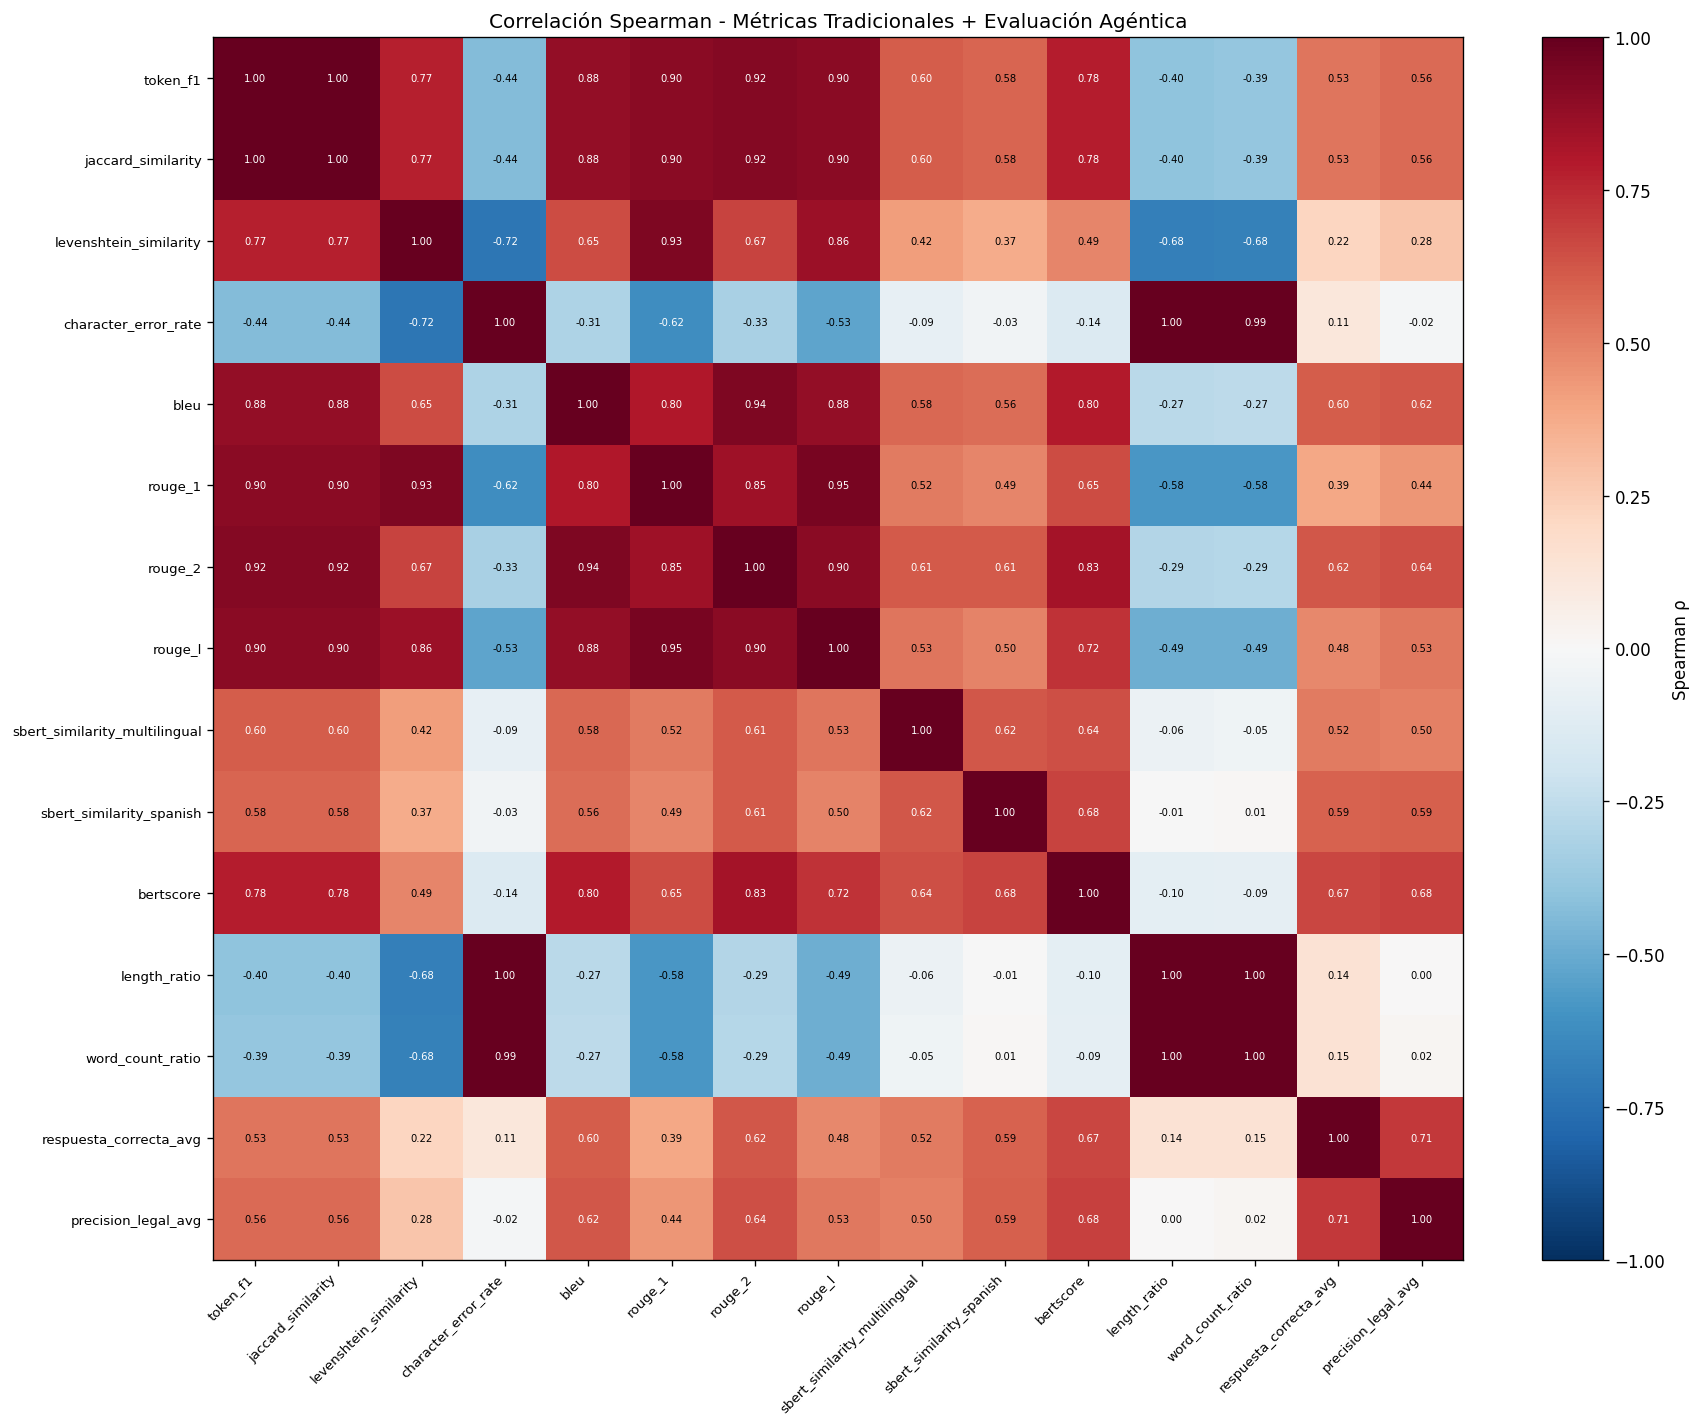

In [15]:
TODAS_LAS_METRICAS = METRICAS_TRADICIONALES + ["respuesta_correcta_avg", "precision_legal_avg"]

all_data = df_combined.select(TODAS_LAS_METRICAS).to_numpy()
n_all = len(TODAS_LAS_METRICAS)

spearman_all = np.zeros((n_all, n_all))
for i in range(n_all):
    for j in range(n_all):
        mask = ~np.isnan(all_data[:, i]) & ~np.isnan(all_data[:, j])
        if mask.sum() > 2:
            rho, _ = stats.spearmanr(all_data[mask, i], all_data[mask, j])
            spearman_all[i, j] = rho
        else:
            spearman_all[i, j] = np.nan

fig, ax = plt.subplots(figsize=(15, 12))
im = ax.imshow(spearman_all, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(n_all))
ax.set_yticks(range(n_all))
ax.set_xticklabels(TODAS_LAS_METRICAS, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(TODAS_LAS_METRICAS, fontsize=8)

for i in range(n_all):
    for j in range(n_all):
        val = spearman_all[i, j]
        if not np.isnan(val):
            color = "white" if abs(val) > 0.6 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6, color=color)

plt.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Correlación Spearman - Métricas Tradicionales + Evaluación Agéntica")
plt.tight_layout()
plt.show()

## 9B. Correlaciones de Spearman vista de a pares

Tabla completa de correlaciones entre todas las métricas (tradicionales + agénticas), ordenada por magnitud descendente.

In [16]:
# Tabla de correlaciones de a pares (todas las métricas)
pares_all = []
for i in range(n_all):
    for j in range(i + 1, n_all):
        rho = spearman_all[i, j]
        if not np.isnan(rho):
            pares_all.append({
                "metrica_1": TODAS_LAS_METRICAS[i],
                "metrica_2": TODAS_LAS_METRICAS[j],
                "spearman_rho": round(rho, 4),
            })

df_pares = pl.DataFrame(pares_all).sort("spearman_rho", descending=True)
print(f"Total de pares: {df_pares.height}")
display(df_pares)

Total de pares: 105


metrica_1,metrica_2,spearman_rho
str,str,f64
"""token_f1""","""jaccard_similarity""",1.0
"""character_error_rate""","""length_ratio""",0.9968
"""length_ratio""","""word_count_ratio""",0.9953
"""character_error_rate""","""word_count_ratio""",0.9922
"""rouge_1""","""rouge_l""",0.9474
…,…,…
"""rouge_1""","""word_count_ratio""",-0.5828
"""character_error_rate""","""rouge_1""",-0.6202
"""levenshtein_similarity""","""word_count_ratio""",-0.6754


## 10. PCA - Análisis de Componentes Principales

Para confirmar cuántos factores latentes explican la varianza.

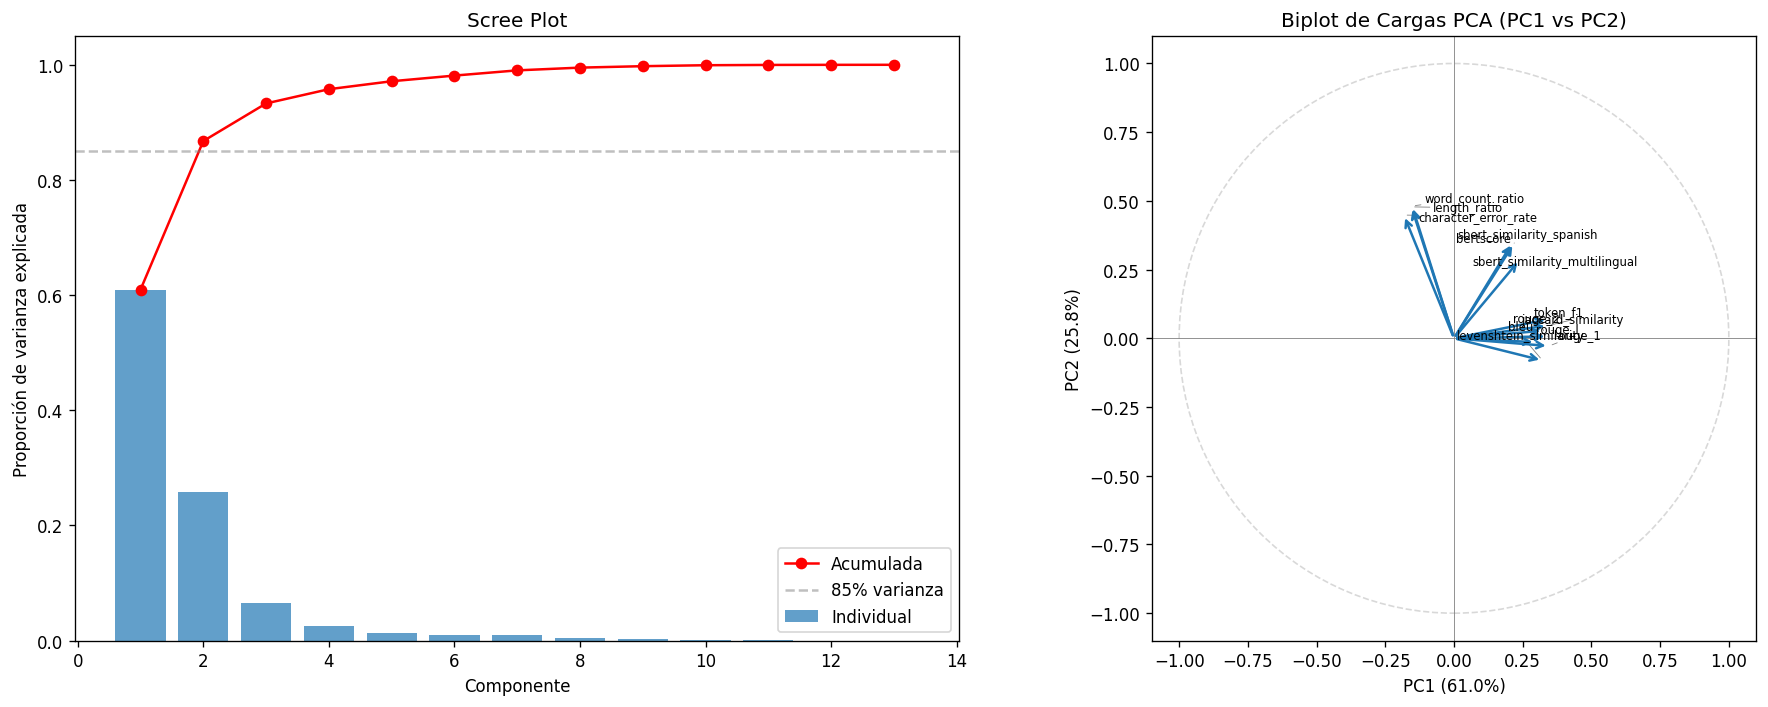


Componentes necesarios para explicar ≥85% de varianza: 2
  PC1: 0.610 (acumulada: 0.610)
  PC2: 0.258 (acumulada: 0.868)
  PC3: 0.065 (acumulada: 0.933)
  PC4: 0.025 (acumulada: 0.958)
  PC5: 0.014 (acumulada: 0.971)
  PC6: 0.010 (acumulada: 0.981)
  PC7: 0.009 (acumulada: 0.990)
  PC8: 0.005 (acumulada: 0.995)
  PC9: 0.003 (acumulada: 0.998)
  PC10: 0.002 (acumulada: 0.999)
  PC11: 0.001 (acumulada: 1.000)
  PC12: 0.000 (acumulada: 1.000)
  PC13: 0.000 (acumulada: 1.000)


In [17]:

from sklearn.preprocessing import StandardScaler
from matplotlib.patches import FancyArrowPatch

# Usar solo métricas tradicionales para PCA (sin NaN)
pca_data = df_wide.select(METRICAS_TRADICIONALES).drop_nulls().to_numpy()

scaler = StandardScaler()
pca_data_scaled = scaler.fit_transform(pca_data)

pca = PCA()
pca.fit(pca_data_scaled)
pca_scores = pca.transform(pca_data_scaled)  # scores para uso posterior

# Varianza explicada
var_explained = pca.explained_variance_ratio_
var_cumulative = np.cumsum(var_explained)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Scree plot
ax1.bar(range(1, len(var_explained) + 1), var_explained, alpha=0.7, label="Individual")
ax1.plot(range(1, len(var_explained) + 1), var_cumulative, "ro-", label="Acumulada")
ax1.axhline(y=0.85, color="gray", linestyle="--", alpha=0.5, label="85% varianza")
ax1.set_xlabel("Componente")
ax1.set_ylabel("Proporción de varianza explicada")
ax1.set_title("Scree Plot")
ax1.legend()

# Biplot: cargas como flechas (vectores de loading)
loadings = pca.components_[:2].T  # (n_metrics, 2)

for i, metrica in enumerate(METRICAS_TRADICIONALES):
    x, y = loadings[i, 0], loadings[i, 1]
    ax2.annotate(
        "",
        xy=(x, y), xytext=(0, 0),
        arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.5),
    )

# Etiquetas con desplazamiento para evitar superposición
from adjustText import adjust_text

texts = []
for i, metrica in enumerate(METRICAS_TRADICIONALES):
    x, y = loadings[i, 0], loadings[i, 1]
    texts.append(ax2.text(x, y, metrica, fontsize=7, ha="center", va="center"))

try:
    adjust_text(texts, ax=ax2, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
except Exception:
    # Fallback: desplazar manualmente si adjustText no está disponible
    for t in texts:
        tx, ty = t.get_position()
        norm = np.sqrt(tx**2 + ty**2)
        if norm > 0:
            t.set_position((tx + 0.03 * tx / norm, ty + 0.03 * ty / norm))

ax2.axhline(0, color="gray", linewidth=0.5)
ax2.axvline(0, color="gray", linewidth=0.5)
ax2.set_xlabel(f"PC1 ({var_explained[0]:.1%})")
ax2.set_ylabel(f"PC2 ({var_explained[1]:.1%})")
ax2.set_title("Biplot de Cargas PCA (PC1 vs PC2)")

# Añadir círculo unitario de referencia
circle = plt.Circle((0, 0), 1, fill=False, color="gray", linestyle="--", alpha=0.3)
ax2.add_patch(circle)
ax2.set_xlim(-1.1, 1.1)
ax2.set_ylim(-1.1, 1.1)
ax2.set_aspect("equal")

plt.tight_layout()
plt.show()

# Resumen
n_components_85 = np.argmax(var_cumulative >= 0.85) + 1
print(f"\nComponentes necesarios para explicar ≥85% de varianza: {n_components_85}")
for i, (v, vc) in enumerate(zip(var_explained, var_cumulative)):
    print(f"  PC{i+1}: {v:.3f} (acumulada: {vc:.3f})")


### 10.1 Matriz de loadings (cargas factoriales)

Las cargas indican cuánto contribuye cada métrica a cada componente principal.
- Valores altos (positivos o negativos) indican fuerte asociación con el componente.
- Métricas con cargas similares en el mismo componente forman un cluster temático.

In [18]:
# Matriz de loadings: componentes retenidos × métricas
n_show = n_components_85 + 1  # mostrar un componente extra para contexto
loadings_full = pca.components_[:n_show].T  # (métricas × componentes)

# Tabla legible
col_names = [f"PC{i+1}" for i in range(n_show)]
df_loadings = pl.DataFrame(
    {"metrica": METRICAS_TRADICIONALES}
    | {col_names[k]: loadings_full[:, k].round(4).tolist() for k in range(n_show)}
)

print(f"Matriz de loadings (primeros {n_show} componentes):\n")
display(df_loadings)

# Identificar la métrica dominante de cada componente
print("\nMétrica con mayor carga absoluta por componente:")
for k in range(n_show):
    abs_loads = np.abs(loadings_full[:, k])
    idx_max = np.argmax(abs_loads)
    print(f"  PC{k+1}: {METRICAS_TRADICIONALES[idx_max]} (carga = {loadings_full[idx_max, k]:+.4f})")

Matriz de loadings (primeros 3 componentes):



metrica,PC1,PC2,PC3
str,f64,f64,f64
"""token_f1""",0.3426,0.0695,0.0675
"""jaccard_similarity""",0.3418,0.0463,0.1403
"""levenshtein_similarity""",0.3221,-0.0806,-0.2426
"""character_error_rate""",-0.1824,0.4486,0.2451
"""bleu""",0.2982,-0.0138,0.5362
…,…,…,…
"""sbert_similarity_multilingual""",0.239,0.2858,-0.3085
"""sbert_similarity_spanish""",0.2188,0.3464,-0.3446
"""bertscore""",0.2124,0.348,-0.3348



Métrica con mayor carga absoluta por componente:
  PC1: rouge_1 (carga = +0.3459)
  PC2: word_count_ratio (carga = +0.4816)
  PC3: bleu (carga = +0.5362)


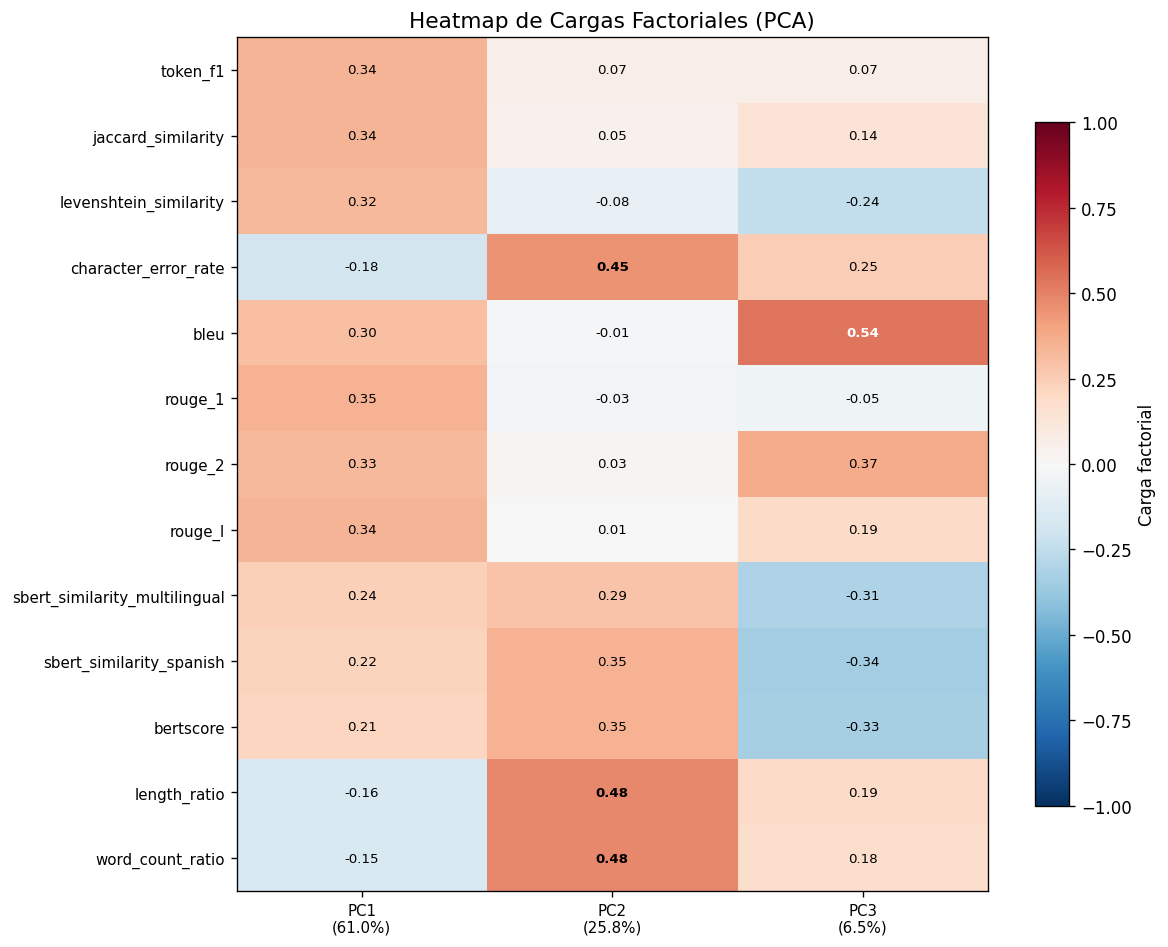

In [19]:
# Heatmap de loadings
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(loadings_full, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")

ax.set_yticks(range(len(METRICAS_TRADICIONALES)))
ax.set_yticklabels(METRICAS_TRADICIONALES, fontsize=9)
ax.set_xticks(range(n_show))
ax.set_xticklabels(
    [f"PC{k+1}\n({var_explained[k]:.1%})" for k in range(n_show)],
    fontsize=9,
)

for i in range(len(METRICAS_TRADICIONALES)):
    for j in range(n_show):
        val = loadings_full[i, j]
        color = "white" if abs(val) > 0.5 else "black"
        weight = "bold" if abs(val) > 0.4 else "normal"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                fontsize=8, color=color, fontweight=weight)

plt.colorbar(im, ax=ax, label="Carga factorial", shrink=0.8)
ax.set_title("Heatmap de Cargas Factoriales (PCA)", fontsize=13)
plt.tight_layout()
plt.show()

### 10.2 Variables suplementarias: métricas agénticas en el espacio PCA

Las métricas agénticas (`respuesta_correcta_avg`, `precision_legal_avg`) se proyectan como **variables suplementarias** (método estándar equivalente al de `FactoMineR` en R): no participan en la construcción de los componentes, pero se proyectan sobre el espacio PCA para revelar su afinidad con los factores latentes.

**Comparabilidad de las flechas:**
- Las flechas **azules** (loadings) representan la correlación de Pearson entre cada métrica tradicional y cada PC — esto es exacto cuando PCA se aplica sobre datos estandarizados (matriz de correlación).
- Las flechas **rojas** usan la **misma métrica** (correlación de Pearson entre los scores PC y la variable suplementaria), por lo que ambas viven en el mismo espacio [-1, 1] y sus longitudes son directamente comparables.
- La longitud de una flecha indica qué fracción de la variabilidad de esa variable queda capturada por el plano PC1–PC2: una flecha corta indica que esa variable tiene componentes importantes fuera de este plano.

> **Nota sobre ordinalidad:** los scores agénticos son promedios de jueces (pseudo-continuos), lo que hace aceptable el uso de Pearson aquí. Si se tratara de scores ordinales sin promediar, correspondería usar Spearman — pero entonces las longitudes ya no serían estrictamente comparables con los loadings azules.

Coordenadas suplementarias (correlación de Pearson con PC1/PC2):
  respuesta_correcta_avg: PC1=+0.488, PC2=+0.429  | cos²(PC1+PC2) = 0.422
  precision_legal_avg: PC1=+0.545, PC2=+0.224  | cos²(PC1+PC2) = 0.348


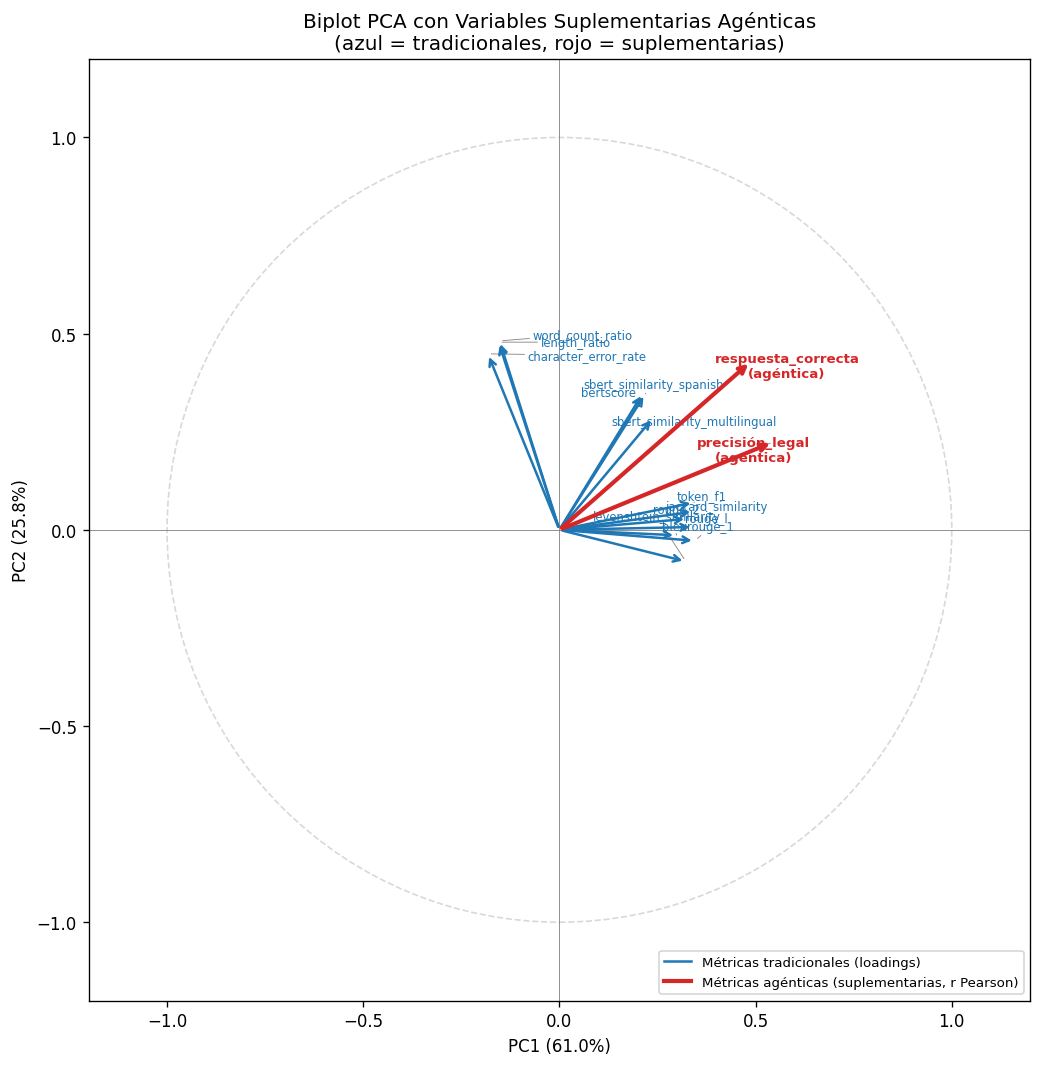

In [20]:
from matplotlib.lines import Line2D

# Alinear observaciones: filas sin NaN en tradicionales NI en agénticas
SUPP_VARS = ["respuesta_correcta_avg", "precision_legal_avg"]
align_cols = METRICAS_TRADICIONALES + SUPP_VARS
aligned_data = df_combined.select(align_cols).drop_nulls().to_numpy()

trad_data_aligned = aligned_data[:, :len(METRICAS_TRADICIONALES)]
supp_data_aligned = aligned_data[:, len(METRICAS_TRADICIONALES):]

# Proyectar con el scaler y PCA ya ajustados
trad_scaled_aligned = scaler.transform(trad_data_aligned)
scores_aligned = pca.transform(trad_scaled_aligned)  # (n_obs, n_components)

# Coordenadas suplementarias = correlación de Pearson entre scores PC y variable suplementaria.
# Esto es equivalente al método estándar de FactoMineR (R) y hace que las flechas rojas
# sean directamente comparables en longitud con los loadings azules (también correlaciones Pearson).
supp_coords = np.zeros((len(SUPP_VARS), 2))
for s_idx in range(len(SUPP_VARS)):
    for pc_idx in range(2):
        r, _ = stats.pearsonr(scores_aligned[:, pc_idx], supp_data_aligned[:, s_idx])
        supp_coords[s_idx, pc_idx] = r

print("Coordenadas suplementarias (correlación de Pearson con PC1/PC2):")
for s_idx, s_name in enumerate(SUPP_VARS):
    r2_plane = supp_coords[s_idx, 0]**2 + supp_coords[s_idx, 1]**2
    print(f"  {s_name}: PC1={supp_coords[s_idx, 0]:+.3f}, PC2={supp_coords[s_idx, 1]:+.3f}  "
          f"| cos²(PC1+PC2) = {r2_plane:.3f}")

# Biplot extendido con variables suplementarias
fig, ax = plt.subplots(figsize=(9, 9))

# Flechas y etiquetas: métricas tradicionales (azul)
texts = []
for i, metrica in enumerate(METRICAS_TRADICIONALES):
    x, y = loadings[i, 0], loadings[i, 1]
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.5))
    texts.append(ax.text(x, y, metrica, fontsize=7, color="#1f77b4", ha="center", va="center"))

# Flechas y etiquetas: variables suplementarias (rojo)
SUPP_LABELS = {
    "respuesta_correcta_avg": "respuesta_correcta\n(agéntica)",
    "precision_legal_avg": "precisión_legal\n(agéntica)",
}
for s_idx, s_name in enumerate(SUPP_VARS):
    sx, sy = supp_coords[s_idx, 0], supp_coords[s_idx, 1]
    ax.annotate("", xy=(sx, sy), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#d62728", lw=2.5))
    texts.append(ax.text(sx, sy, SUPP_LABELS[s_name], fontsize=8, color="#d62728",
                         fontweight="bold", ha="center", va="center"))

try:
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
except Exception:
    pass

# Decoraciones
circle = plt.Circle((0, 0), 1, fill=False, color="gray", linestyle="--", alpha=0.3)
ax.add_patch(circle)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({var_explained[0]:.1%})")
ax.set_ylabel(f"PC2 ({var_explained[1]:.1%})")
ax.set_title("Biplot PCA con Variables Suplementarias Agénticas\n(azul = tradicionales, rojo = suplementarias)")

legend_elements = [
    Line2D([0], [0], color="#1f77b4", lw=1.5, label="Métricas tradicionales (loadings)"),
    Line2D([0], [0], color="#d62728", lw=2.5, label="Métricas agénticas (suplementarias, r Pearson)"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Interpretación del biplot — cuatro grupos de métricas

El biplot revela cuatro clusters con perfiles conceptuales bien diferenciados:

---

#### Grupo 1 — Métricas de longitud y cantidad (`word_count_ratio`, `length_ratio`, `character_error_rate`)

Estas métricas **no miden contenido sino volumen**: cuánto se escribió en relación a la referencia, o cuántos caracteres difieren. Son prácticamente independientes del significado — una respuesta larga pero incorrecta puede puntuar bien aquí. Su posición en el cuadrante superior-izquierdo del biplot indica que capturan una dimensión ortogonal al resto: el eje de *extensión de la respuesta*.

`character_error_rate` aparece con signo invertido respecto a `length_ratio` (es una medida de error, no de similitud), lo que explica que sus flechas apunten en sentido opuesto.

---

#### Grupo 2 — Embeddings neurales (`bertscore`, `sbert_similarity_spanish`, `sbert_similarity_multilingual`)

Estas métricas comparten el mecanismo fundamental: **comparar representaciones densas** generadas por transformers (BERT, SBERT). Capturan *similitud semántica* robusta al parafraseo — dos oraciones con palabras completamente distintas pero mismo significado obtienen scores altos. Se agrupan porque todas proyectan el texto al mismo tipo de espacio vectorial continuo de alta dimensión, donde la proximidad refleja significado compartido, no lexia compartida.

---

#### Grupo 3 — Similitud léxica / n-gramas (`token_f1`, `jaccard_similarity`, `levenshtein_similarity`, `bleu`, `rouge_1`, `rouge_2`, `rouge_l`)

Todas estas métricas cuentan **coincidencias de tokens o n-gramas** entre la respuesta y la referencia. No tienen capacidad de generalización semántica: si la respuesta dice "normativa" en lugar de "ley", el score cae aunque el significado sea el mismo. Se agrupan porque varían solo en el nivel de abstracción del conteo: unigramas (`rouge_1`, `token_f1`, `jaccard`), bigramas (`rouge_2`), secuencias más largas (`rouge_l`, `bleu`), o edición de caracteres (`levenshtein`). Son fundamentalmente variantes del mismo principio.

---

#### Grupo 4 — Métricas agénticas (`respuesta_correcta_avg`, `precision_legal_avg`)

La separación entre estas dos variables es el hallazgo más interesante:

- **`respuesta_correcta_avg`** se proyecta cerca del cluster de embeddings neurales. El juez LLM evalúa si la respuesta es *correcta en sentido general* — lo que implica comprensión del significado global, tolerancia al parafraseo y valoración del argumento más allá de las palabras exactas. Esto es precisamente lo que miden los embeddings semánticos.

- **`precision_legal_avg`** se sitúa más cerca del cluster léxico. La precisión en derecho exige el uso de **terminología técnica específica**: artículos, incisos, nombres de normas, fechas. Un juez LLM que evalúa precisión legal penaliza la omisión de esos términos concretos, comportándose de modo más parecido a las métricas de n-gramas que a las de embeddings.

Esta disociación sugiere que **los dos criterios agénticos miden aspectos complementarios e irreductibles**: uno captura corrección semántica global y el otro captura fidelidad lexical al dominio legal — lo que justifica retener ambos como variables de respuesta independientes.

## 11. Selección de VR recomendada

Basado en el análisis de correlación y PCA, se identifican las métricas representativas:

**Criterio**: si dos métricas tienen |ρ| > 0.85, se conserva la más informativa.

**Métricas sugeridas:**
- **Léxica representativa**: `token_f1` o `rouge_l` (representan el cluster léxico)
- **Semántica embedding**: `sbert_similarity_spanish` (idioma nativo)
- **Semántica contextual**: `bertscore`
- **Evaluación agéntica**: `respuesta_correcta_avg`, `precision_legal_avg`

Ajustar esta selección en base a los resultados observados arriba.

In [22]:
import json

# Métricas seleccionadas (ajustar según resultados)
VR_SELECCIONADAS = [
    # "token_f1",
    # "rouge_l",
    # "sbert_similarity_spanish",
    # "bertscore",
    "respuesta_correcta_avg",
    # "precision_legal_avg",
]

# Guardar la selección en un archivo JSON compartido para los demás notebooks
vr_config = {
    "vr_seleccionadas": VR_SELECCIONADAS,
    "descripcion": "Variables de Respuesta seleccionadas en 01_exploracion_descriptiva_correlacion para uso en todos los notebooks de part_j.",
}
vr_path = Path("vr_seleccionadas.json")
vr_path.write_text(json.dumps(vr_config, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"VR guardadas en {vr_path.resolve()}")

print("\nVariables de Respuesta seleccionadas:")
for vr in VR_SELECCIONADAS:
    print(f"  - {vr}")

# Guardar dataset combinado para los siguientes notebooks
df_combined.write_csv(DATA_DIR / "combined_metrics_for_analysis.csv")
print(f"\nDataset combinado guardado: {df_combined.shape}")

VR guardadas en /mnt/c/Users/leo24/OneDrive/ex_dropbox/tesis/examples/notebooks/part_j/vr_seleccionadas.json

Variables de Respuesta seleccionadas:
  - respuesta_correcta_avg

Dataset combinado guardado: (711, 22)
